# Explore normal network traffic and DoS attacks

We want to understand the data before choosing an anomaly-detection method.

We follow the class examples: **look at the data → draw simple plots → compare variables → explain what we see → define the task**. The main references are the temperature notebook 01b and the raw-data exploration in engine notebook 07a.

We use the combined CSV. We do not train a model or create a training/testing split.

## 1. What does one row mean?

A **packet** is a small piece of network communication. A **flow** groups packets belonging to an exchange. Each row summarizes one recorded flow:

- **Source:** the side recorded as sending in the forward direction.
- **Destination:** the other side; its packet and byte counts describe traffic in the return direction.
- A flow can have packets in only one direction. A long conversation can also be recorded in several rows.

A **DoS attack** tries to make a service unavailable to its users, for example by overwhelming it with traffic or requests. A busy website or large file download can also produce heavy traffic, so a large value alone does not prove an attack. [CISA explanation](https://www.cisa.gov/sites/default/files/publications/understanding-and-responding-to-ddos-attacks_508c.pdf)

For a security team, missed attacks can interrupt service, while too many false alerts waste time and may lead to blocking legitimate traffic. Our aim is to identify flows worth investigating.

This is a laboratory dataset with normal activity and generated attacks. We kept only Normal and DoS records. Its attack percentage does not tell us how common attacks are on a real network. [Dataset source](https://research.unsw.edu.au/projects/unsw-nb15-dataset)

### What do the columns mean?

| Columns | Simple meaning | Unit |
|---|---|---|
| `proto` | Protocol: the rules used for communication, such as TCP or UDP | Category |
| `service` | Service, such as web browsing or DNS | Category |
| `state` | Recorded state of the exchange; its meaning depends on the protocol | Category |
| `dur` | How long the recorded flow lasted | Seconds |
| `spkts`, `dpkts` | Packets sent forward and returned | Packets |
| `sbytes`, `dbytes` | Bytes sent forward and returned | Bytes |
| `rate` | Packet rate during the recorded flow | Packets/second |
| `sload`, `dload` | Data sent per second in each direction | Bits/second |
| `sinpkt`, `dinpkt` | Average time between packets in each direction | Milliseconds |
| `is_anomaly` | Given label: 0 = Normal, 1 = DoS | Label |

Bytes here are recorded network bytes, not just file or message contents. A zero return count means no return packets were recorded; it does not automatically mean an attack. Units and states follow the [Argus manual](https://openargus.org/oldsite/man/man1/ra.1.pdf).

In [40]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run the notebook from the project folder.
data = pd.read_csv("content/normal_dos.csv", keep_default_na=False)

categorical = ["proto", "service", "state"]
numeric = ["dur", "spkts", "dpkts", "sbytes", "dbytes", "rate", "sload", "dload", "sinpkt", "dinpkt"]
features = categorical + numeric
X = data[features].copy()
y = data["is_anomaly"].copy()

normal = data[data["is_anomaly"] == 0]
dos = data[data["is_anomaly"] == 1]
colors = ["#0072B2", "#D55E00"]

# Figures can also be opened outside the notebook.
figures = Path("content/exploration/simple_figures")
figures.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 16)

print("Rows:", len(data))
print("Selected features:", len(features))
display(data.head())

Rows: 109353
Selected features: 13


,proto,service,state,dur,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sinpkt,dinpkt,is_anomaly
0,tcp,-,FIN,0.121478,6,4,258,172,74.087490,14158.942380,8495.365234,24.295600,8.375000,0
1,tcp,-,FIN,0.649902,14,38,734,42014,78.473372,8395.112305,503571.312500,49.915000,15.432865,0
2,tcp,-,FIN,1.623129,8,16,364,13186,14.170161,1572.271851,60929.230470,231.875571,102.737203,0
3,tcp,ftp,FIN,1.681642,12,12,628,770,13.677108,2740.178955,3358.622070,152.876547,90.235726,0
4,tcp,-,FIN,0.449454,10,6,534,268,33.373826,8561.499023,3987.059814,47.750333,75.659602,0


## 2. Check the data

First check the size, missing values and basic statistics, as we did before plotting the class datasets. We keep all records while exploring.

Column types:


proto             str
service           str
state             str
dur           float64
spkts           int64
dpkts           int64
sbytes          int64
dbytes          int64
rate          float64
sload         float64
dload         float64
sinpkt        float64
dinpkt        float64
is_anomaly      int64
dtype: object

Missing values:


proto         0
service       0
state         0
dur           0
spkts         0
dpkts         0
sbytes        0
dbytes        0
rate          0
sload         0
dload         0
sinpkt        0
dinpkt        0
is_anomaly    0
dtype: int64

Negative numerical values: 0
Infinite numerical values: 0
Empty category names: 0
Different values in each column:


proto        133
service       13
state         10
dur        62746
spkts        441
dpkts        373
sbytes      3514
dbytes      2197
rate       67210
sload      70833
dload      68006
sinpkt     66225
dinpkt     62430
dtype: int64

,Flows,Percent
Normal,93000,85.0
DoS,16353,15.0


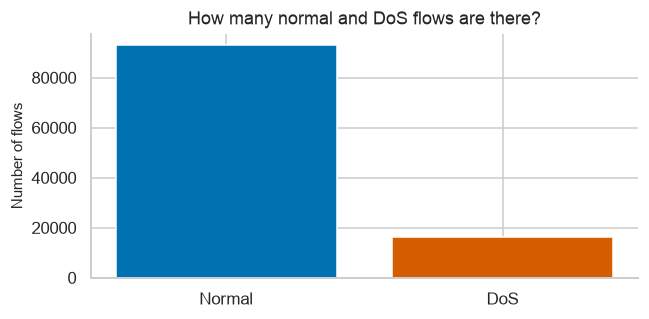

In [41]:
print("Column types:")
display(data.dtypes)
print("Missing values:")
display(data.isna().sum())
print("Negative numerical values:", int((X[numeric] < 0).sum().sum()))
print("Infinite numerical values:", int(np.isinf(X[numeric]).sum().sum()))
print("Empty category names:", int(X[categorical].eq("").sum().sum()))
print("Different values in each column:")
display(X.nunique())

counts = pd.Series({"Normal": len(normal), "DoS": len(dos)})
display(pd.DataFrame({"Flows": counts, "Percent": (100 * counts / len(data)).round(1)}))

plt.figure(figsize=(6, 3))
plt.bar(counts.index, counts.values, color=colors)
plt.ylabel("Number of flows")
plt.title("How many normal and DoS flows are there?")
plt.tight_layout()
plt.savefig(figures / "01_class_counts.png")
plt.show()
plt.close()

**What do we see?** There are 93,000 Normal and 16,353 DoS records. About 15% are labeled DoS. There are no missing, negative or infinite numerical values. We still need to understand zeros and unusual values; passing these checks does not make every record easy to interpret.

In [42]:
# Same values in the selected 13 features, regardless of the label.
print("Repeated rows of measurements:", data.duplicated(subset=features).sum())

label_counts = data.groupby(features)["is_anomaly"].nunique()
print("Sets of identical measurements with both labels:", (label_counts > 1).sum())

# A comparison only: the original data is not changed.
different_rows = data.drop_duplicates(subset=features + ["is_anomaly"])
print("DoS percentage in all rows:", round(100 * data["is_anomaly"].mean(), 1))
print("DoS percentage after counting each feature-and-label combination once:",
      round(100 * different_rows["is_anomaly"].mean(), 1))

Repeated rows of measurements: 26869
Sets of identical measurements with both labels: 24
DoS percentage in all rows: 15.0
DoS percentage after counting each feature-and-label combination once: 5.6


**What does this mean?** Many flows share the same measurements. Repeated traffic or repeated/rounded records could explain this; we cannot tell which without more information. Repetition changes how common a pattern looks, so we keep that in mind rather than deleting rows.

There are **24 sets of identical measurements with both labels**. The selected columns do not contain everything needed to distinguish those records. Adding ratios calculated from the same columns will not resolve that difference.

## 3. Understand the categories

`proto`, `service` and `state` describe different parts of the communication.

| Protocol value | Meaning |
|---|---|
| `tcp` | Communication with connection setup and reliable delivery, commonly used for web and email traffic |
| `udp` | Sends individual messages without a TCP-style connection setup |
| `arp` | Finds the local network address needed to reach a device |
| `icmp` | Diagnostic and error messages, such as ping |
| `igmp` | Manages membership in multicast groups |
| `ospf` | Routers exchanging information about network paths |
| `unas` | The exporter did not provide a named protocol; this is not one identified application |

There are 133 protocol names, including old and uncommon names. The complete meanings and uncertain entries are in the [domain notes](skills/DOMAIN_NOTES.md) and [category dictionary](categorical_value_dictionary.csv).

We show all service and state meanings below. `-` in `service` means the service was not identified/provided. `INT` does not always mean a failed TCP connection: interpret it together with `proto`.

In [43]:
services = {
    "-": "Service not identified",
    "dhcp": "Gives devices an IP address and network settings",
    "dns": "Looks up domain names, such as a website name",
    "ftp": "Commands used to arrange a file transfer",
    "ftp-data": "The file data being transferred by FTP",
    "http": "Web requests and responses",
    "irc": "Online chat messages",
    "pop3": "Retrieving email from a server",
    "radius": "Checking network access and keeping access records",
    "smtp": "Sending and forwarding email",
    "snmp": "Monitoring and managing network devices",
    "ssh": "Encrypted remote access and related file transfers",
    "ssl": "The dataset's label for SSL/TLS-related encrypted traffic",
}
states = {
    "ACC": "A request was answered",
    "CON": "An active or continuing exchange was recorded",
    "ECO": "An ICMP echo request, used by ping",
    "FIN": "TCP ending was observed",
    "INT": "Initial state; often a one-way observation",
    "PAR": "ICMP reported a problem with an IP header",
    "REQ": "A request was recorded",
    "RST": "A TCP reset was observed",
    "URN": "ICMP reported that a network could not be reached",
    "no": "Meaning not confirmed; keep this value as recorded",
}
print("Service values:")
display(pd.DataFrame(services.items(), columns=["Value", "Meaning"]))
print("State values — read together with the protocol:")
display(pd.DataFrame(states.items(), columns=["Value", "Meaning"]))

Service values:


,Value,Meaning
0,-,Service not identified
1,dhcp,Gives devices an IP address and network settings
2,dns,"Looks up domain names, such as a website name"
3,ftp,Commands used to arrange a file transfer
4,ftp-data,The file data being transferred by FTP
5,http,Web requests and responses
6,irc,Online chat messages
7,pop3,Retrieving email from a server
8,radius,Checking network access and keeping access rec...
9,smtp,Sending and forwarding email


State values — read together with the protocol:


,Value,Meaning
0,ACC,A request was answered
1,CON,An active or continuing exchange was recorded
2,ECO,"An ICMP echo request, used by ping"
3,FIN,TCP ending was observed
4,INT,Initial state; often a one-way observation
5,PAR,ICMP reported a problem with an IP header
6,REQ,A request was recorded
7,RST,A TCP reset was observed
8,URN,ICMP reported that a network could not be reached
9,no,Meaning not confirmed; keep this value as reco...


### Which categories occur in normal and attack traffic?

The bar charts show the percentage **within each class**. For example, a blue bar of 50% means half of the Normal flows use that category. This makes the shapes comparable even though there are more Normal records.

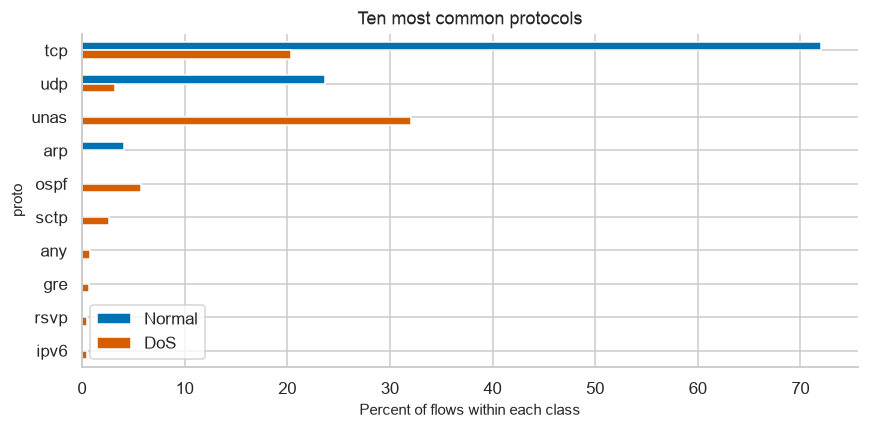

proto — number of flows:


,Normal,DoS
proto,,
tcp,66969,3336
udp,22019,527
unas,0,5246
arp,3846,0
ospf,102,944
sctp,0,426
any,0,132
gre,0,107
rsvp,0,88


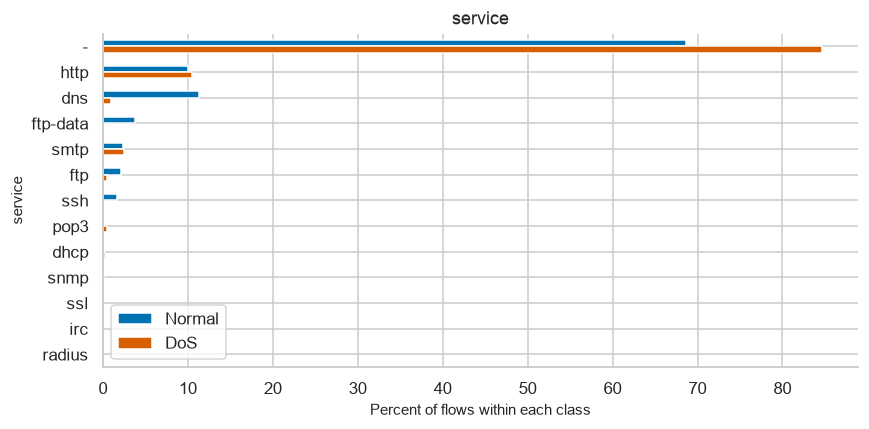

service — number of flows:


,Normal,DoS
service,,
-,63887,13845
http,9361,1709
dns,10561,147
ftp-data,3501,14
smtp,2214,402
ftp,1976,73
ssh,1491,0
pop3,4,87
dhcp,0,42


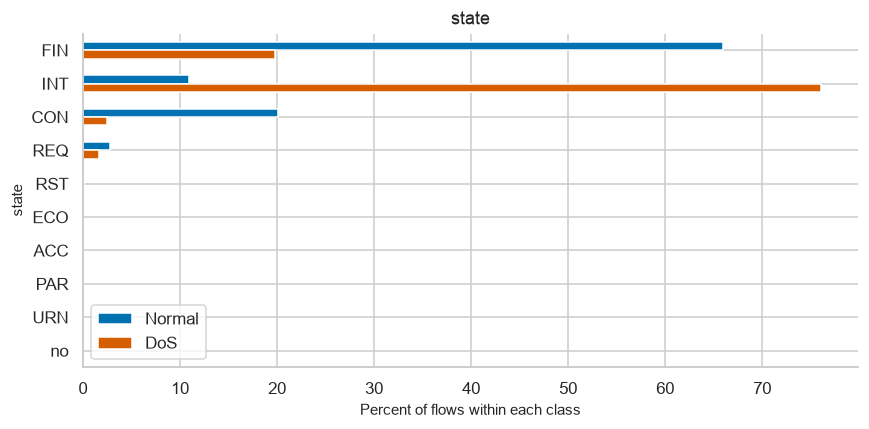

state — number of flows:


,Normal,DoS
state,,
FIN,61347,3237
INT,10200,12439
CON,18732,407
REQ,2632,268
RST,72,2
ECO,12,0
ACC,2,0
PAR,1,0
URN,1,0


In [44]:
for feature in categorical:
    counts = pd.crosstab(data[feature], data["is_anomaly"])
    counts = counts.reindex(columns=[0, 1], fill_value=0)
    counts.columns = ["Normal", "DoS"]
    counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]

    percentages = 100 * counts / [len(normal), len(dos)]
    if feature == "proto":
        # Keep the chart readable. All protocol names stay in the data.
        percentages = percentages.head(10)
        title = "Ten most common protocols"
    else:
        title = feature

    percentages.plot.barh(figsize=(8, 4), color=colors)
    plt.xlabel("Percent of flows within each class")
    plt.ylabel(feature)
    plt.title(title)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig(figures / f"02_{feature}_counts.png")
    plt.show()
    plt.close()

    print(feature, "— number of flows:")
    display(counts.head(13))

In [45]:
# Check how many protocol names have no normal examples in this dataset.
protocol_counts = pd.crosstab(data["proto"], data["is_anomaly"])
protocol_counts = protocol_counts.reindex(columns=[0, 1], fill_value=0)
only_dos = protocol_counts[protocol_counts[0] == 0]

print("Protocol names without Normal examples:", len(only_dos))
print("Percent of DoS records using these names:",
      round(100 * only_dos[1].sum() / len(dos), 1))

Protocol names without Normal examples: 126
Percent of DoS records using these names: 70.6


**What do we see?** TCP and UDP occur in both classes. `FIN` and `INT` also occur in both classes. A service or state name alone is therefore not a complete explanation of an attack.

126 protocol names have no Normal examples here, and 70.6% of DoS records use those names. This could make the dataset easier than a real network. It does not mean these protocols are always malicious. Later, we should distinguish a new protocol from unusual behavior within a familiar protocol.

## 4. Look at each numerical variable

We start with the original measurements. The mean and standard deviation summarize the data, while the median and quartiles are less affected by a few very large values. This is the same reason we used robust statistics in the temperature example.

In [46]:
print("Summary of all numerical measurements:")
display(X[numeric].describe().round(3))

comparison = pd.DataFrame({
    "Normal mean": normal[numeric].mean(),
    "DoS mean": dos[numeric].mean(),
    "Normal median": normal[numeric].median(),
    "DoS median": dos[numeric].median(),
})
display(comparison.round(3))

Summary of all numerical measurements:


,dur,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sinpkt,dinpkt
count,109353.000,109353.000,109353.000,1.093530e+05,1.093530e+05,109353.000,1.093530e+05,1.093530e+05,109353.000,109353.000
mean,1.230,27.048,31.267,6.226179e+03,2.548154e+04,38517.113,4.376300e+07,1.523753e+06,2005.501,124.281
std,5.762,106.351,150.419,1.211829e+05,1.992933e+05,113420.969,1.745830e+08,3.520368e+06,10451.829,1479.927
min,0.000,1.000,0.000,2.400000e+01,0.000000e+00,0.000,0.000000e+00,0.000000e+00,0.000,0.000
25%,0.001,2.000,2.000,2.000000e+02,8.600000e+01,28.651,1.151318e+04,6.675080e+02,0.010,0.002
50%,0.037,10.000,8.000,8.640000e+02,3.540000e+02,1396.927,4.502699e+05,2.116378e+04,1.393,0.655
75%,0.711,22.000,18.000,2.558000e+03,3.380000e+03,4681.497,1.737126e+06,6.890756e+05,65.214,54.790
max,60.000,8669.000,11018.000,1.163118e+07,1.465753e+07,1000000.003,5.344000e+09,2.242273e+07,60009.992,57739.240


,Normal mean,DoS mean,Normal median,DoS median
dur,1.015000e+00,2.449000e+00,0.054,0.000000e+00
spkts,2.756300e+01,2.411700e+01,10.000,2.000000e+00
dpkts,3.302800e+01,2.125200e+01,8.000,0.000000e+00
sbytes,4.092444e+03,1.836079e+04,1040.000,2.000000e+02
dbytes,2.613820e+04,2.174713e+04,642.000,0.000000e+00
rate,1.958829e+04,1.461659e+05,642.326,1.111111e+05
sload,2.976812e+07,1.233523e+08,298195.844,8.888889e+07
dload,1.788697e+06,1.700825e+04,75919.188,0.000000e+00
sinpkt,2.344196e+03,7.933500e+01,3.027,9.000000e-03
dinpkt,1.427880e+02,1.903300e+01,1.030,0.000000e+00


### Histograms: use a scale that shows both small and large values

Some columns range from very small numbers to very large ones. Equal-width bars over the full range put almost everything in the first bar.

The plots below use a **logarithmic horizontal scale**: moving from 1 to 10 takes the same space as moving from 10 to 100. The labels still show the actual values and units, not the logarithm of the values.

- Blue = Normal; orange = DoS. The vertical axis counts flows in each bar.
- Both classes use the same bars and axis range for a given measurement.
- **Zero cannot be placed on a logarithmic axis.** Its count is shown in the table first. No rows are removed from the dataset.
- There are more Normal flows, so taller blue bars alone do not mean a value is more typical of Normal traffic.

Durations are shown in milliseconds, bytes in kB (1,000 bytes), and loads in Mbit/s (1,000,000 bits/s). Packet counts and packet rates keep their original units.

Zero values, counted separately from the plots:


,Normal,DoS
dur,3543,11
spkts,0,0
dpkts,12849,12707
sbytes,0,0
dbytes,12849,12707
rate,3528,133
sload,3536,133
dload,12864,12707
sinpkt,343,133
dinpkt,12869,12707


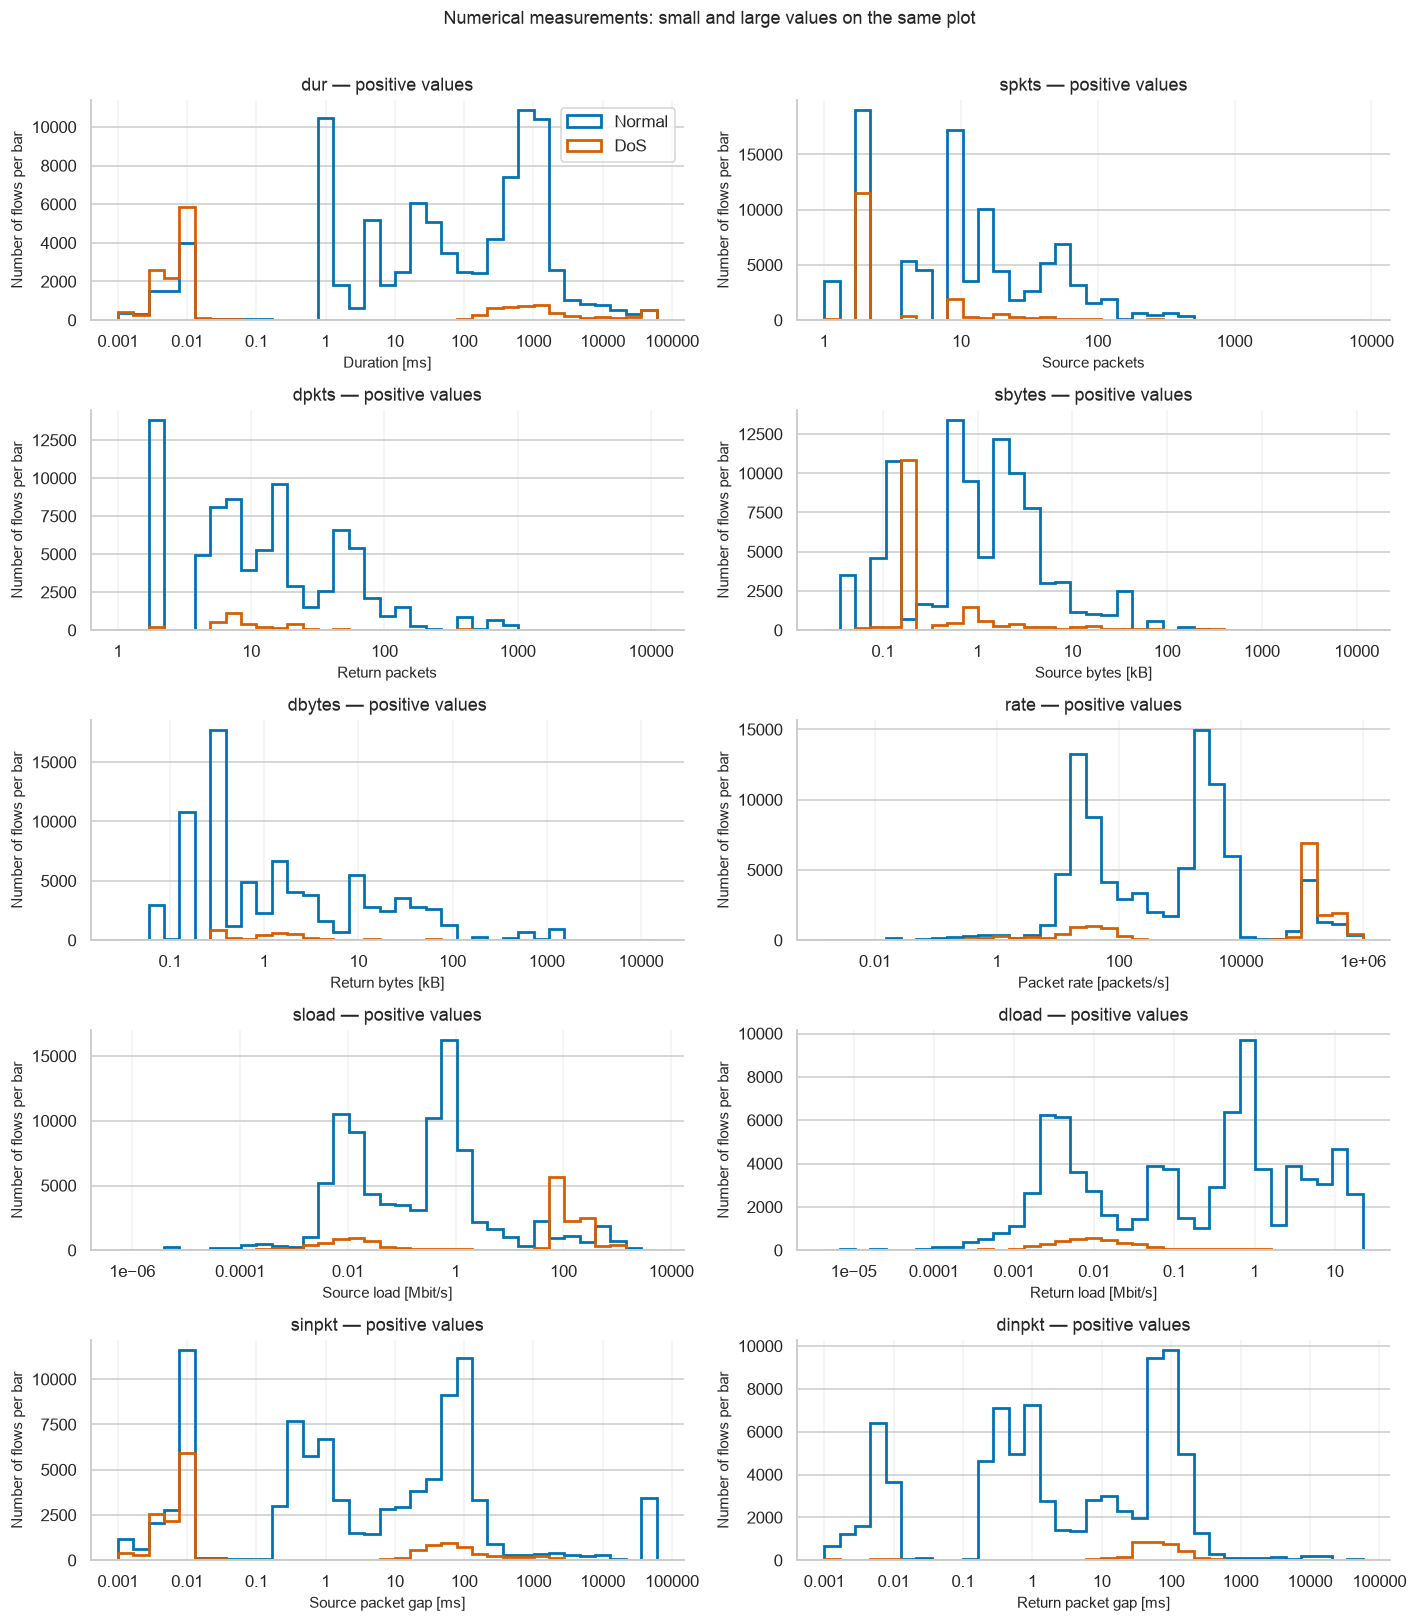

In [47]:
from matplotlib.ticker import StrMethodFormatter

plot_labels = {
    "dur": "Duration [ms]", "spkts": "Source packets", "dpkts": "Return packets",
    "sbytes": "Source bytes [kB]", "dbytes": "Return bytes [kB]",
    "rate": "Packet rate [packets/s]",
    "sload": "Source load [Mbit/s]", "dload": "Return load [Mbit/s]",
    "sinpkt": "Source packet gap [ms]", "dinpkt": "Return packet gap [ms]",
}
# Divide by these values to get the units printed on the axes.
scale = {"dur": 0.001, "sbytes": 1000, "dbytes": 1000,
         "sload": 1000000, "dload": 1000000}

print("Zero values, counted separately from the plots:")
display(pd.DataFrame({"Normal": normal[numeric].eq(0).sum(),
                      "DoS": dos[numeric].eq(0).sum()}))

fig, axes = plt.subplots(5, 2, figsize=(13, 15))
for ax, feature in zip(axes.flat, numeric):
    divisor = scale.get(feature, 1)
    positive = data.loc[data[feature] > 0, feature] / divisor
    bins = np.geomspace(positive.min(), positive.max(), 36)

    ax.hist(normal.loc[normal[feature] > 0, feature] / divisor, bins=bins,
            histtype="step", linewidth=1.8, color=colors[0], label="Normal")
    ax.hist(dos.loc[dos[feature] > 0, feature] / divisor, bins=bins,
            histtype="step", linewidth=1.8, color=colors[1], label="DoS")
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.set_xlabel(plot_labels[feature])
    ax.set_ylabel("Number of flows per bar")
    ax.set_title(feature + " — positive values")
    ax.grid(axis="x", alpha=.25)
axes[0, 0].legend()
plt.suptitle("Numerical measurements: small and large values on the same plot")
plt.tight_layout(rect=[0, 0, 1, .97])
plt.savefig(figures / "03_histograms_full_range.png")
plt.show()
plt.close()

### Close-up with ordinary axes

The plots above show the full positive range. We also use an ordinary, evenly spaced axis for a closer look at three useful ranges, as we did when zooming into the class examples.

The first plot shows flows lasting **up to 100 microseconds** (0.0001 seconds). The other plots show up to 100 source packets and up to 20,000 packets/second. Zero values are included here. We print the percentage of each class inside each close-up so it is clear how much of the data is shown.

Duration [microseconds] — percent shown: Normal 12.4 DoS 70.8
Source packets — percent shown: Normal 95.5 DoS 97.7
Packet rate [packets/s] — percent shown: Normal 91.6 DoS 30.0


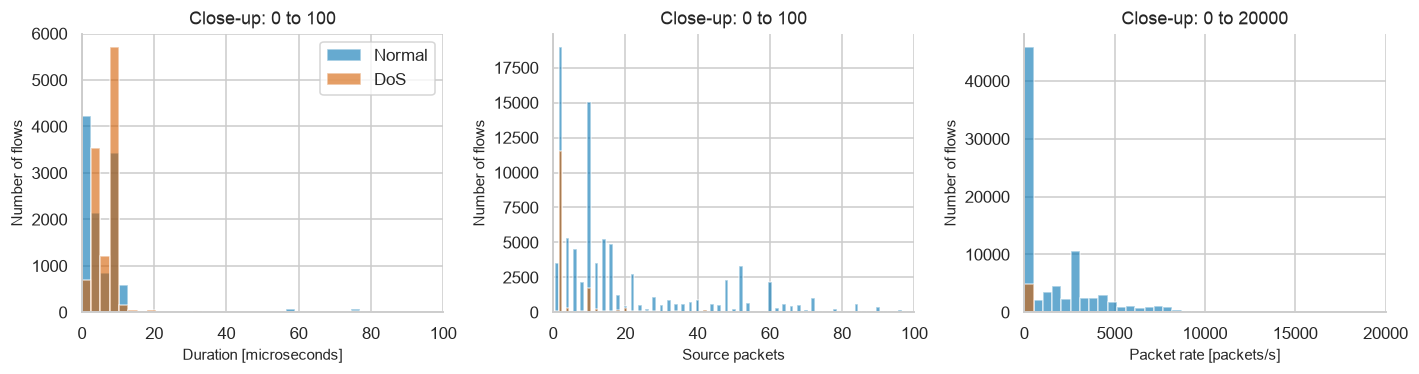

In [48]:
zoom_features = ["dur", "spkts", "rate"]
zoom_limits = [100, 100, 20000]
zoom_divisors = [0.000001, 1, 1]
zoom_labels = ["Duration [microseconds]", "Source packets", "Packet rate [packets/s]"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, feature, limit, divisor, label in zip(axes, zoom_features, zoom_limits, zoom_divisors, zoom_labels):
    normal_values = normal[feature] / divisor
    dos_values = dos[feature] / divisor
    # One bar per packet for packet counts; ordinary equal-width bars elsewhere.
    bins = np.arange(-.5, 101.5, 1) if feature == "spkts" else np.linspace(0, limit, 40)
    ax.hist(normal_values, bins=bins, color=colors[0], alpha=.6, label="Normal")
    ax.hist(dos_values, bins=bins, color=colors[1], alpha=.6, label="DoS")
    ax.set_xlim(0, limit)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of flows")
    ax.set_title(f"Close-up: 0 to {limit:g}")
    print(label, "— percent shown:",
          "Normal", round(100 * normal_values.between(0, limit).mean(), 1),
          "DoS", round(100 * dos_values.between(0, limit).mean(), 1))
axes[0].legend()
plt.tight_layout()
plt.savefig(figures / "04_histograms_zoom.png")
plt.show()
plt.close()

**What does this mean?** Many DoS records contain only two source packets and have a very short duration. Their packet rate can still be high: two packets separated by 10 microseconds correspond to about 100,000 packets per second over that short gap. It does not mean this record contains 100,000 packets.

The DoS median duration is 0.000009 seconds, but its mean is about 2.45 seconds. The long flows pull the mean upward. We should not describe all DoS flows with one average.

,Normal,DoS
dur,3.8,0.1
spkts,0.0,0.0
dpkts,13.8,77.7
sbytes,0.0,0.0
dbytes,13.8,77.7
rate,3.8,0.8
sload,3.8,0.8
dload,13.8,77.7
sinpkt,0.4,0.8
dinpkt,13.8,77.7


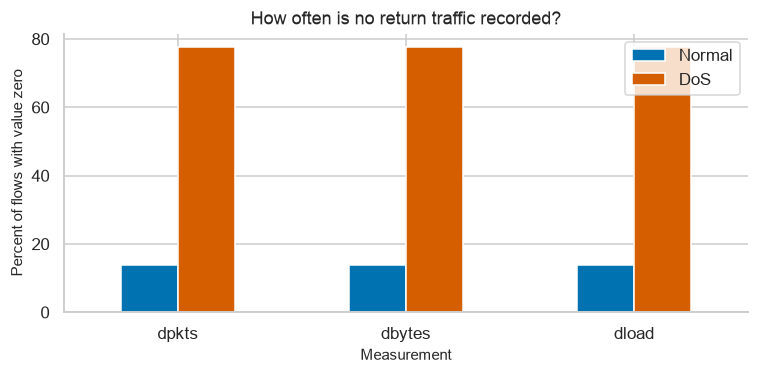

In [49]:
zero_percent = pd.DataFrame({
    "Normal": 100 * normal[numeric].eq(0).mean(),
    "DoS": 100 * dos[numeric].eq(0).mean(),
})
display(zero_percent.round(1))

zero_percent.loc[["dpkts", "dbytes", "dload"]].plot.bar(figsize=(7, 3.5), color=colors)
plt.ylabel("Percent of flows with value zero")
plt.xlabel("Measurement")
plt.title("How often is no return traffic recorded?")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figures / "05_zero_return_traffic.png")
plt.show()
plt.close()

**What do we see?** About 77.7% of DoS records and 13.8% of Normal records have no return packets. This is a useful difference, but not a rule that identifies every attack.

One-way communication can be normal. Also, a zero packet-gap value is hard to interpret when fewer than two packets were recorded. We need to look at the protocol and packet counts together.

## 5. Compare variables: scatterplots and a pairplot

A scatterplot puts two measurements of the same flow on its two axes. Each dot is a flow. We show a random sample of 2,000 flows to avoid covering the page with dots, as in the engine notebook. The tables and histograms use all records.

Sample counts:


is_anomaly
Normal    1695
DoS        305
Name: count, dtype: int64

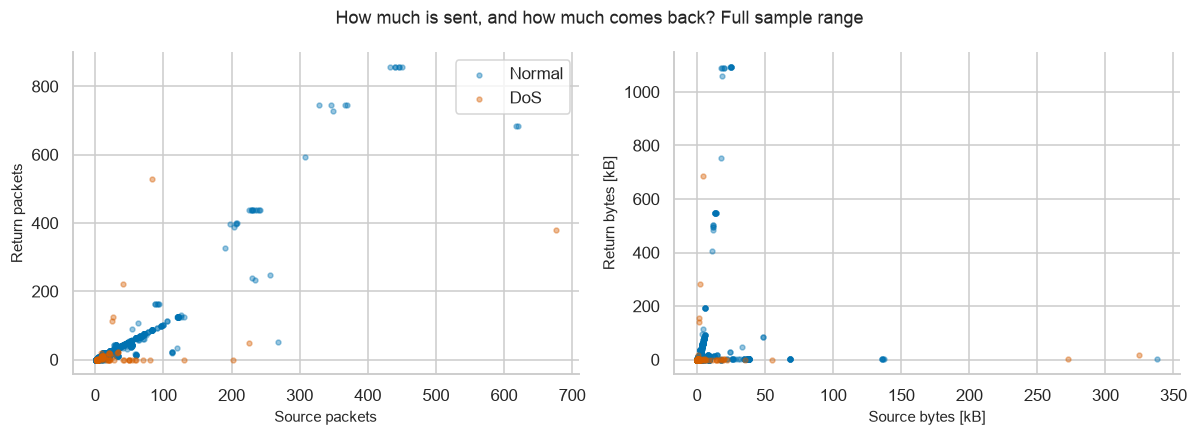

In [50]:
sample = data.sample(n=2000, random_state=42)
print("Sample counts:")
display(sample["is_anomaly"].value_counts().rename(index={0: "Normal", 1: "DoS"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for value, name, color in [(0, "Normal", colors[0]), (1, "DoS", colors[1])]:
    group = sample[sample["is_anomaly"] == value]
    axes[0].scatter(group["spkts"], group["dpkts"], s=10, alpha=.4, color=color, label=name)
    axes[1].scatter(group["sbytes"] / 1000, group["dbytes"] / 1000,
                    s=10, alpha=.4, color=color, label=name)
axes[0].set_xlabel("Source packets")
axes[0].set_ylabel("Return packets")
axes[1].set_xlabel("Source bytes [kB]")
axes[1].set_ylabel("Return bytes [kB]")
axes[0].legend()
plt.suptitle("How much is sent, and how much comes back? Full sample range")
plt.tight_layout()
plt.savefig(figures / "06_scatterplots.png")
plt.show()
plt.close()

### Pairplot: a closer look at packet counts

This follows the simple pairplot in notebook 01b:

- The diagonal contains histograms: **packet count on x, number of flows on y**.
- The other two plots compare source and return packet counts. Each plot names both axes.
- The two scatterplots show the same relationship with the axes exchanged.

We zoom to flows with at most 100 packets in each direction. The full range is shown above. The numbers on the axes are actual packet counts: there is no log transformation.

Sample flows shown in this zoom: 1920 out of 2000


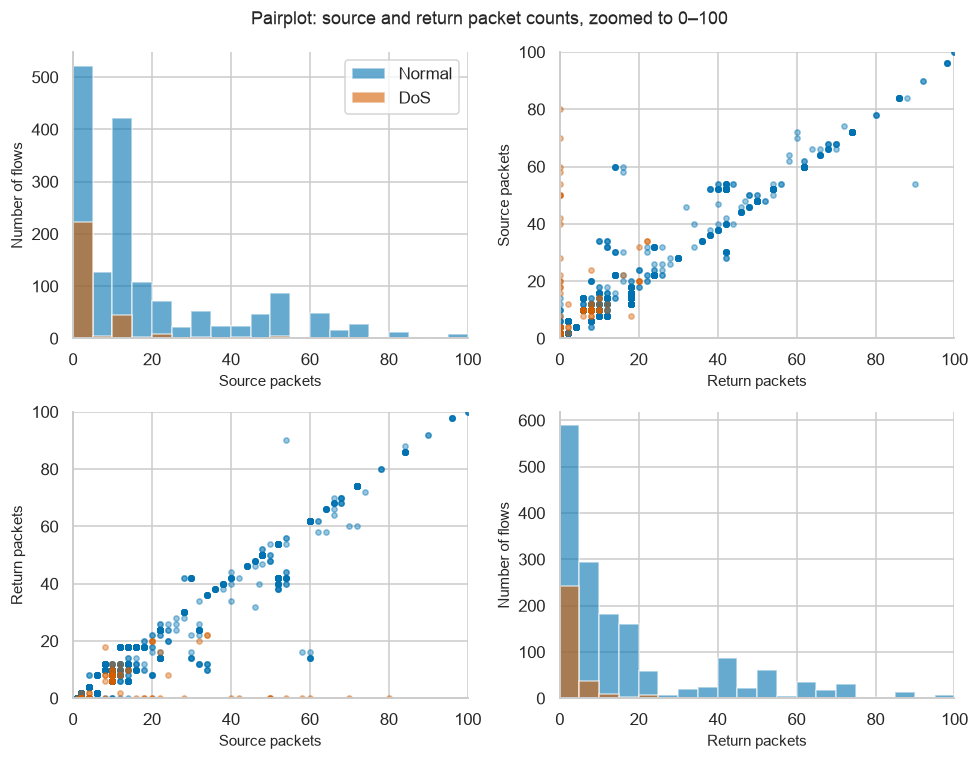

In [51]:
pair_data = sample[(sample["spkts"] <= 100) & (sample["dpkts"] <= 100)]
print("Sample flows shown in this zoom:", len(pair_data), "out of", len(sample))

variables = ["spkts", "dpkts"]
names = {"spkts": "Source packets", "dpkts": "Return packets"}
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for row, y_column in enumerate(variables):
    for col, x_column in enumerate(variables):
        ax = axes[row, col]
        for value, name, color in [(0, "Normal", colors[0]), (1, "DoS", colors[1])]:
            group = pair_data[pair_data["is_anomaly"] == value]
            if row == col:
                ax.hist(group[x_column], bins=np.arange(0, 105, 5),
                        color=color, alpha=.6, label=name)
            else:
                ax.scatter(group[x_column], group[y_column], s=12, alpha=.4, color=color)
        ax.set_xlabel(names[x_column])
        ax.set_xlim(0, 100)
        if row == col:
            ax.set_ylabel("Number of flows")
        else:
            ax.set_ylabel(names[y_column])
            ax.set_ylim(0, 100)
axes[0, 0].legend()
plt.suptitle("Pairplot: source and return packet counts, zoomed to 0–100")
plt.tight_layout()
plt.savefig(figures / "07_simple_pairplot.png")
plt.show()
plt.close()

**What do we see?** Sending more packets often goes with receiving more packets, but there are also flows with little or no return traffic. The classes overlap. A combination of measurements may be more useful than looking at one column alone.

We should also compare similar types of communication. This is like the class example where bearing temperature had to be understood together with ambient temperature.

### Relationships between features: scatterplots

These are feature-against-feature plots, like the scatterplots in class. **Each dot is one flow.** Blue means Normal and orange means DoS.

Read the labels on each plot: the horizontal axis shows one measurement and the vertical axis another. An upward pattern means larger values often occur together. A spread of dots means the relationship varies.

We use the same random sample of 2,000 flows with seed 42. Some plots are close-ups so the common values are visible. Their axis limits and the percentage of each class shown are reported below. The original data stays unchanged.

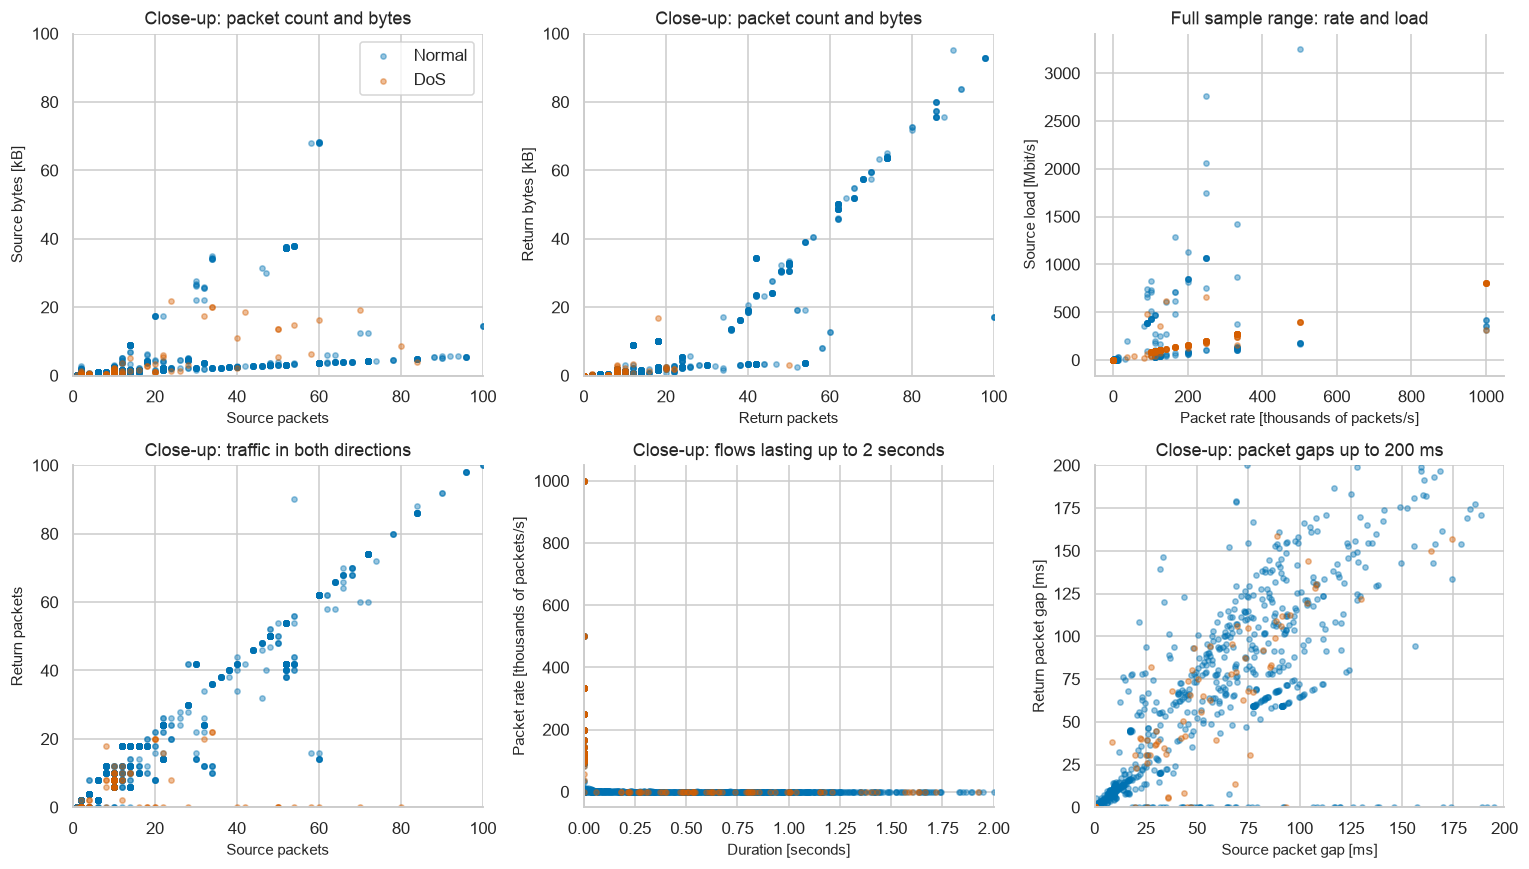

Percent of each class inside the close-ups (all records):


,Normal,DoS
Source packets / bytes,95.5,97.7
Return packets / bytes,95.5,98.3
Source / return packets,95.2,97.2
Duration / rate,94.2,91.0
Source / return packet gaps,91.6,93.0


In [52]:
correlation_sample = data.sample(n=2000, random_state=42)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for value, name, color in [(0, "Normal", colors[0]), (1, "DoS", colors[1])]:
    group = correlation_sample[correlation_sample["is_anomaly"] == value]
    axes[0].scatter(group["spkts"], group["sbytes"] / 1000, s=12, alpha=.4, color=color, label=name)
    axes[1].scatter(group["dpkts"], group["dbytes"] / 1000, s=12, alpha=.4, color=color)
    axes[2].scatter(group["rate"] / 1000, group["sload"] / 1000000, s=12, alpha=.4, color=color)
    axes[3].scatter(group["spkts"], group["dpkts"], s=12, alpha=.4, color=color)
    axes[4].scatter(group["dur"], group["rate"] / 1000, s=12, alpha=.4, color=color)
    axes[5].scatter(group["sinpkt"], group["dinpkt"], s=12, alpha=.4, color=color)

axes[0].set_xlabel("Source packets")
axes[0].set_ylabel("Source bytes [kB]")
axes[1].set_xlabel("Return packets")
axes[1].set_ylabel("Return bytes [kB]")
axes[2].set_xlabel("Packet rate [thousands of packets/s]")
axes[2].set_ylabel("Source load [Mbit/s]")
axes[3].set_xlabel("Source packets")
axes[3].set_ylabel("Return packets")
axes[4].set_xlabel("Duration [seconds]")
axes[4].set_ylabel("Packet rate [thousands of packets/s]")
axes[5].set_xlabel("Source packet gap [ms]")
axes[5].set_ylabel("Return packet gap [ms]")

for ax in axes[:2]:
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_title("Close-up: packet count and bytes")
axes[2].set_title("Full sample range: rate and load")
axes[3].set_xlim(0, 100)
axes[3].set_ylim(0, 100)
axes[3].set_title("Close-up: traffic in both directions")
axes[4].set_xlim(0, 2)
axes[4].set_title("Close-up: flows lasting up to 2 seconds")
axes[5].set_xlim(0, 200)
axes[5].set_ylim(0, 200)
axes[5].set_title("Close-up: packet gaps up to 200 ms")
axes[0].legend()
plt.tight_layout()
plt.savefig(figures / "11_correlation_scatterplots.png")
plt.show()
plt.close()

# Show how much of the complete dataset is inside each close-up.
coverage = pd.DataFrame(index=["Source packets / bytes", "Return packets / bytes",
                               "Source / return packets", "Duration / rate", "Source / return packet gaps"])
for group, name in [(normal, "Normal"), (dos, "DoS")]:
    coverage[name] = [
        100 * ((group["spkts"] <= 100) & (group["sbytes"] <= 100000)).mean(),
        100 * ((group["dpkts"] <= 100) & (group["dbytes"] <= 100000)).mean(),
        100 * ((group["spkts"] <= 100) & (group["dpkts"] <= 100)).mean(),
        100 * (group["dur"] <= 2).mean(),
        100 * ((group["sinpkt"] <= 200) & (group["dinpkt"] <= 200)).mean(),
    ]
print("Percent of each class inside the close-ups (all records):")
display(coverage.round(1))

**What do the plots help us see?** More packets often go with more bytes, but the amount of data per packet varies. The source/return plot shows that some flows have little return traffic. Rate and duration need to be read together: a very short flow can have a high rate even with few packets.

The colors help us see where Normal and DoS overlap and where their patterns differ. We should compare similar protocols and services before calling a point unusual. These plots show relationships; they do not establish a rule for detecting attacks.

**Why is this useful for anomaly detection?** Two measurements may be ordinary on their own but unusual together. For example, we can ask whether a flow carries an unusual number of bytes for its packet count, compared with similar normal traffic.

Strongly related columns may repeat some information, but we do not remove them automatically. Correlation does not prove that one feature causes another, or that either feature detects an attack. These plots help us decide which relationships deserve attention later.

Median packet rate [packets/second]:


,Normal,DoS
All protocols,642.3,111111.1
TCP,104.8,37.7
UDP,2941.2,100000.0


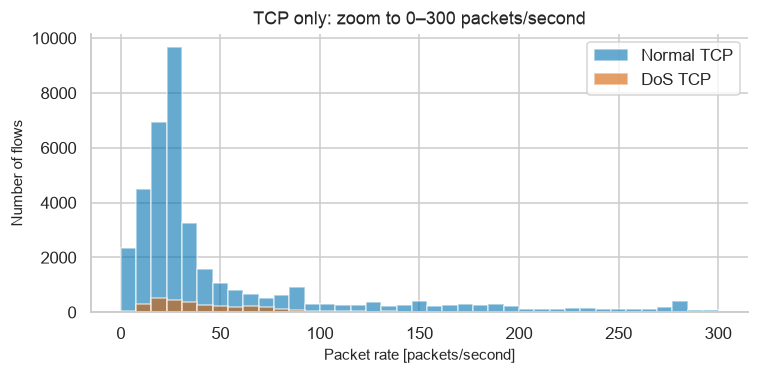

Percent inside this zoom: Normal TCP 58.0 DoS TCP 100.0


In [53]:
# Compare packet rates overall and within the two main protocols.
rate_medians = pd.DataFrame({
    "Normal": [normal["rate"].median(),
               normal.loc[normal["proto"] == "tcp", "rate"].median(),
               normal.loc[normal["proto"] == "udp", "rate"].median()],
    "DoS": [dos["rate"].median(),
            dos.loc[dos["proto"] == "tcp", "rate"].median(),
            dos.loc[dos["proto"] == "udp", "rate"].median()],
}, index=["All protocols", "TCP", "UDP"])
print("Median packet rate [packets/second]:")
display(rate_medians.round(1))

# Focus on TCP and use the same bins for both groups.
normal_tcp = normal[normal["proto"] == "tcp"]
dos_tcp = dos[dos["proto"] == "tcp"]
plt.figure(figsize=(7, 3.5))
plt.hist(normal_tcp["rate"], bins=np.linspace(0, 300, 40), color=colors[0], alpha=.6, label="Normal TCP")
plt.hist(dos_tcp["rate"], bins=np.linspace(0, 300, 40), color=colors[1], alpha=.6, label="DoS TCP")
plt.xlabel("Packet rate [packets/second]")
plt.ylabel("Number of flows")
plt.title("TCP only: zoom to 0–300 packets/second")
plt.legend()
plt.tight_layout()
plt.savefig(figures / "08_tcp_rate.png")
plt.show()
plt.close()
print("Percent inside this zoom: Normal TCP", round(100 * normal_tcp["rate"].between(0, 300).mean(), 1),
      "DoS TCP", round(100 * dos_tcp["rate"].between(0, 300).mean(), 1))

**What does this mean?** Overall, DoS has a higher median packet rate. Within TCP, DoS has a **lower** median rate: about 38 versus 105 packets/second. The mix of protocols changes the overall comparison.

Therefore, “high rate means attack” is too simple. We need to compare a flow with similar normal traffic. Protocol, service and state help us decide what “similar” means.

In [54]:
# Compare common combinations of protocol, service and state.
context_counts = pd.crosstab(
    [data["proto"], data["service"], data["state"]], data["is_anomaly"]
).reindex(columns=[0, 1], fill_value=0)
context_counts.columns = ["Normal", "DoS"]
context_counts["Total"] = context_counts["Normal"] + context_counts["DoS"]
display(context_counts.sort_values("Total", ascending=False).head(10))

Normal   DoS  Total
proto service  state                     
tcp   -        FIN     42838   929  43767
      http     FIN      9349  1699  11048
udp   dns      CON     10506    34  10540
      -        INT      6391   268   6659
unas  -        INT         0  5246   5246
udp   -        CON      5038    82   5120
arp   -        INT      3695     0   3695
tcp   ftp-data FIN      3495    14   3509
      -        CON      3010    75   3085
      smtp     FIN      2211   393   2604

**What do we see?** Normal traffic includes several different kinds of communication: web traffic, DNS, file transfers and others. There are also both labels within some of the same protocol/service/state groups. We cannot expect a single small range of values to describe every normal flow.

## 6. Two useful extra features

We derive two simple summaries from the selected columns:

1. **Return packet share:** `dpkts / (spkts + dpkts)`. A value of 0 means no return packets, 0.5 means equal counts in both directions, and a value near 1 means mostly return packets.
2. **Source bytes per packet:** `sbytes / spkts`. This helps describe whether the source sends smaller or larger packets. It is not the size of application content alone.

The packet sum is only an intermediate calculation within one flow; it does not count connections or a flood across many flows. We leave a ratio undefined if its denominator is zero. The original dataset is unchanged.

Undefined values:


Return packet share        0
Source bytes per packet    0
dtype: int64

Medians, using the given labels:


,Return packet share,Source bytes per packet
is_anomaly,,
Normal,0.5,73.0
DoS,0.0,100.0


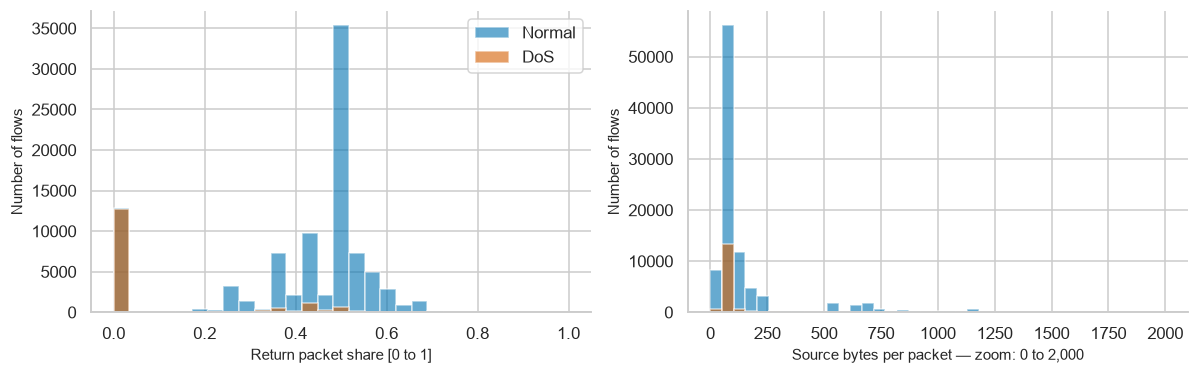

Source bytes/packet above the second plot's range: 0


In [55]:
extra = pd.DataFrame(index=data.index)
extra["Return packet share"] = data["dpkts"] / (data["spkts"] + data["dpkts"]).replace(0, np.nan)
extra["Source bytes per packet"] = data["sbytes"] / data["spkts"].replace(0, np.nan)

print("Undefined values:")
display(extra.isna().sum())
print("Medians, using the given labels:")
display(extra.groupby(data["is_anomaly"]).median().rename(index={0: "Normal", 1: "DoS"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for value, name, color in [(0, "Normal", colors[0]), (1, "DoS", colors[1])]:
    mask = y == value
    axes[0].hist(extra.loc[mask, "Return packet share"].dropna(), bins=np.linspace(0, 1, 30),
                 color=color, alpha=.6, label=name)
    axes[1].hist(extra.loc[mask, "Source bytes per packet"].dropna(), bins=np.linspace(0, 2000, 40),
                 color=color, alpha=.6, label=name)
axes[0].set_xlabel("Return packet share [0 to 1]")
axes[1].set_xlabel("Source bytes per packet — zoom: 0 to 2,000")
for ax in axes:
    ax.set_ylabel("Number of flows")
axes[0].legend()
plt.tight_layout()
plt.savefig(figures / "09_extra_features.png")
plt.show()
plt.close()
print("Source bytes/packet above the second plot's range:", (extra["Source bytes per packet"] > 2000).sum())

**What does this mean?** Return packet share makes the difference between one-way and two-way flows easy to read. Source bytes per packet gives another way to compare communication patterns. Neither adds new measurements: both are calculated from columns we already have. We keep them because they are easy to explain, not because we have shown that they improve a model.

## 7. Look at actual flows

As in the examples, return to individual rows to check the explanation. We show a few normal and DoS web flows in the same broad setting, plus the Normal record with the largest amount of return data.

In [56]:
web = data[(data["proto"] == "tcp") & (data["service"] == "http") & (data["state"] == "FIN")]
columns = ["proto", "service", "state", "dur", "spkts", "dpkts", "sbytes", "dbytes", "rate", "is_anomaly"]

print("Normal web flows — first three matching rows:")
display(web.loc[web["is_anomaly"] == 0, columns].head(3))
print("DoS web flows — first three matching rows:")
display(web.loc[web["is_anomaly"] == 1, columns].head(3))
print("Normal record with the most return bytes:")
display(data.loc[[normal["dbytes"].idxmax()], columns])

Normal web flows — first three matching rows:


,proto,service,state,dur,spkts,dpkts,sbytes,dbytes,rate,is_anomaly
17,tcp,http,FIN,0.393556,10,8,860,1096,43.195886,0
21,tcp,http,FIN,0.338017,10,6,998,268,44.376468,0
28,tcp,http,FIN,0.546425,10,8,1168,1040,31.111315,0


DoS web flows — first three matching rows:


,proto,service,state,dur,spkts,dpkts,sbytes,dbytes,rate,is_anomaly
47954,tcp,http,FIN,0.601736,18,10,10476,1576,44.870175,1
47959,tcp,http,FIN,0.220081,10,8,836,1056,77.244287,1
47962,tcp,http,FIN,0.250314,38,10,42398,440,187.764170,1


Normal record with the most return bytes:


,proto,service,state,dur,spkts,dpkts,sbytes,dbytes,rate,is_anomaly
41980,tcp,http,FIN,15.202358,260,1716,11564,2249492,129.914055,0


**What should we remember?** There are large Normal flows, and there are DoS flows with fairly ordinary-looking counts. Large return data could come from a legitimate download, but these columns do not tell us what was downloaded. An attack label and an extreme value are not the same thing.

The examples are illustrations, not proof of a rule. The histograms and summary tables describe how common the patterns are.

## 8. What is our anomaly-detection task?

> **Find individual network flows that behave differently from similar normal traffic, and investigate whether those flows correspond to the given DoS labels.**

| Question | Our answer |
|---|---|
| What is one observation? | One recorded network flow. |
| What would an alert mean? | This flow deserves a security analyst's attention. It does not by itself prove an outage. |
| What do we use? | The 13 selected features, with the two simple summaries above if useful. The label is kept separate. |
| What is normal? | Several kinds of legitimate communication. Compare flows within a suitable protocol/service/state setting. |
| What kind of anomaly? | An unusual individual flow, possibly unusual only in its setting. |
| Can we detect a collective attack here? | Not directly. We lack timestamps and host identifiers needed to group many flows by target and time. |
| What learning setting could come next? | Learn normal behavior from Normal examples and look for anomalies. |

**Why this task?** We found that high rates, missing return traffic and protocol names can help describe differences, but none is a universal attack rule. TCP and UDP behave differently. Some identical measurements also have both labels, so the selected data cannot explain every case.

For later work, distinguish **protocols with no Normal examples** from **unusual behavior in protocols that have both labels**. Otherwise, a method could rely mainly on the protocol names specific to this dataset.

We used labels to understand this dataset. We have not shown how well any method detects future attacks. Before a later model comparison, we will need a separate evaluation plan that considers repeated rows, missed attacks and false alerts. No model is fitted here.

### References

- Class examples: `references/WPI_AnoDet_01b_AD_statistical_solution.ipynb` (histograms, zooms and pairplots), `references/WM_AnDet_07a_PCA_AE_NCMAPSS.ipynb` (raw-data exploration and sampled pairplots), and the single/two-state machine examples (compare similar conditions).
- [Course toolkit](skills/COURSE_TOOLKIT.md) and [course source index](skills/COURSE_SOURCES.md).
- [UNSW dataset](https://research.unsw.edu.au/projects/unsw-nb15-dataset), [Argus field definitions](https://openargus.org/oldsite/man/man1/ra.1.pdf), and [CISA explanation of DoS](https://www.cisa.gov/sites/default/files/publications/understanding-and-responding-to-ddos-attacks_508c.pdf).
- [All categorical value meanings](skills/DOMAIN_NOTES.md), with the [complete category dictionary](categorical_value_dictionary.csv).

Run all cells from the project folder using its `.venv` environment. Install dependencies from `requirements.txt`. The figures are also saved in `content/exploration/simple_figures/`.